# Лабораторная работа № 3

**Вариант:** 0  
**Датасет:** CIFAR-10  
**Количество классов:** 10  
**Размер изображения:** 32 × 32 пикселя, RGB  
**Основная модель:** собственная свёрточная нейронная сеть (CNN)  
**Transfer learning:** MobileNetV2 (`mobilenetv2_100`)


In [3]:
!pip -q install timm scikit-learn pandas

In [4]:
import os
import copy
import time
import random
import json
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader
from torchvision import datasets
from torchvision.transforms import v2

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import timm

SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()


DEVICE = torch.device("cpu")
torch.set_num_threads(min(4, os.cpu_count() or 1))

## 1. Подготовка данных

Для варианта 0 используется CIFAR-10. Датасет содержит 60 000 цветных изображений размером 32 × 32 пикселя: 50 000 изображений в обучающей части и 10 000 в тестовой. Изображения относятся к десяти классам.

In [18]:
VARIANT = 0

DATA_ROOT = "./data"
OUTPUT_DIR = Path("./outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

IMG_SIZE = 32
NUM_CLASSES = 10
BATCH_SIZE = 32

LEARNING_RATE = 1e-3
EPOCHS = 30
DROPOUT = min(0.1 * VARIANT, 0.5)

BACKBONE_NAME = "mobilenetv2_100"
HEAD_EPOCHS = 5
FINE_EPOCHS = 5
HEAD_LR = 1e-3

N_UNFREEZE = (VARIANT % 3) + 1
FINE_LR = max(1e-4 / (2 ** N_UNFREEZE), 1e-5)

IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

CLASS_NAMES = [
    "airplane",
    "automobile",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck"
]

print("Вариант:", VARIANT)
print("Датасет: CIFAR-10")
print("Размер входа:", IMG_SIZE, "×", IMG_SIZE)
print("Backbone:", BACKBONE_NAME)
print("Learning rate CNN:", LEARNING_RATE)
print("Эпох CNN:", EPOCHS)
print("Dropout:", DROPOUT)
print("Этап fine-tuning: размораживаем блоков =", N_UNFREEZE)
print("Fine-tuning LR:", FINE_LR)

Вариант: 0
Датасет: CIFAR-10
Размер входа: 32 × 32
Backbone: mobilenetv2_100
Learning rate CNN: 0.001
Эпох CNN: 30
Dropout: 0.0
Этап fine-tuning: размораживаем блоков = 1
Fine-tuning LR: 5e-05


In [6]:
def build_train_transform():
    return v2.Compose([
        v2.Resize((IMG_SIZE, IMG_SIZE), antialias=True),
        v2.RandomHorizontalFlip(p=0.5),
        v2.RandAugment(num_ops=2, magnitude=9),
        v2.ToImage(),
        v2.ToDtype(torch.float32, scale=True),
        v2.Normalize(IMAGENET_MEAN, IMAGENET_STD),
        v2.RandomErasing(
            p=0.25,
            scale=(0.02, 0.15),
            ratio=(0.3, 3.3)
        )
    ])

def build_eval_transform():
    return v2.Compose([
        v2.Resize((IMG_SIZE, IMG_SIZE), antialias=True),
        v2.ToImage(),
        v2.ToDtype(torch.float32, scale=True),
        v2.Normalize(IMAGENET_MEAN, IMAGENET_STD)
    ])

base_train = datasets.CIFAR10(
    root=DATA_ROOT,
    train=True,
    download=True,
    transform=None
)

base_test = datasets.CIFAR10(
    root=DATA_ROOT,
    train=False,
    download=True,
    transform=None
)

print("Исходная обучающая выборка:", len(base_train))
print("Тестовая выборка:", len(base_test))
print("Классы:", base_train.classes)

100%|██████████| 170M/170M [47:44<00:00, 59.5kB/s]


Исходная обучающая выборка: 50000
Тестовая выборка: 10000
Классы: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [7]:
class TransformDataset(Dataset):

    def __init__(self, base_dataset, indices, transform):
        self.base_dataset = base_dataset
        self.indices = list(indices)
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, index):
        image, label = self.base_dataset[self.indices[index]]
        image = self.transform(image)
        return image, int(label)

generator = torch.Generator().manual_seed(SEED)
indices = torch.randperm(
    len(base_train),
    generator=generator
).tolist()

n_val = int(0.10 * len(indices))

val_indices = indices[:n_val]
train_indices = indices[n_val:]

train_ds = TransformDataset(
    base_train,
    train_indices,
    build_train_transform()
)

val_ds = TransformDataset(
    base_train,
    val_indices,
    build_eval_transform()
)

test_ds = TransformDataset(
    base_test,
    range(len(base_test)),
    build_eval_transform()
)

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    generator=torch.Generator().manual_seed(SEED)
)

val_loader = DataLoader(
    val_ds,
    batch_size=128,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_ds,
    batch_size=128,
    shuffle=False,
    num_workers=0
)

print(f"Train: {len(train_ds)} изображений")
print(f"Validation: {len(val_ds)} изображений")
print(f"Test: {len(test_ds)} изображений")

Train: 45000 изображений
Validation: 5000 изображений
Test: 10000 изображений


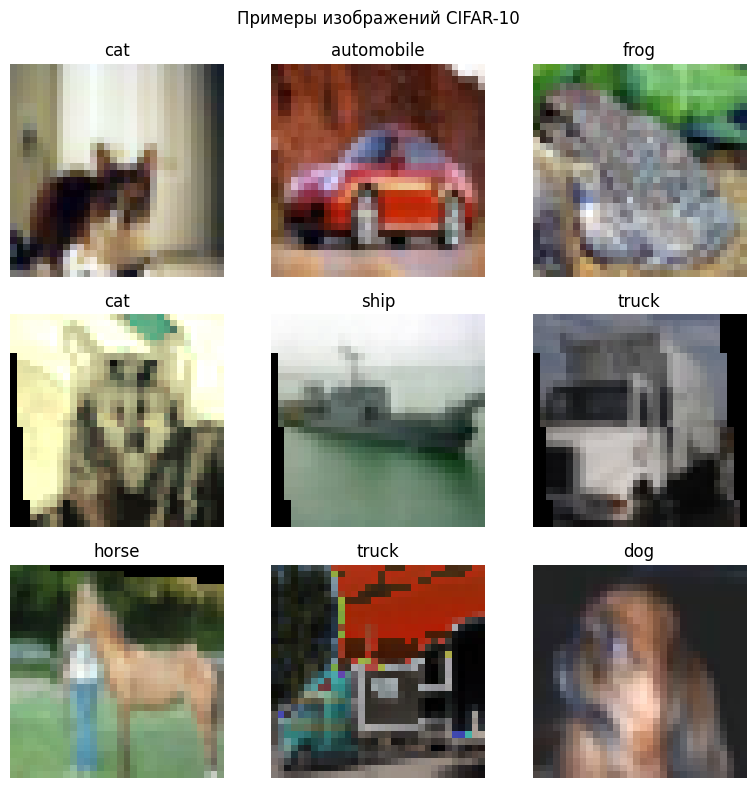

In [8]:
def denormalize(images):
    mean = torch.tensor(IMAGENET_MEAN).view(1, 3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(1, 3, 1, 1)
    return (images.cpu() * std + mean).clamp(0, 1)

images, labels = next(iter(train_loader))
images_vis = denormalize(images[:9])

fig, axes = plt.subplots(3, 3, figsize=(8, 8))

for ax, image, label in zip(axes.flat, images_vis, labels[:9]):
    ax.imshow(image.permute(1, 2, 0).numpy())
    ax.set_title(CLASS_NAMES[int(label)])
    ax.axis("off")

fig.suptitle("Примеры изображений CIFAR-10")
plt.tight_layout()
plt.show()

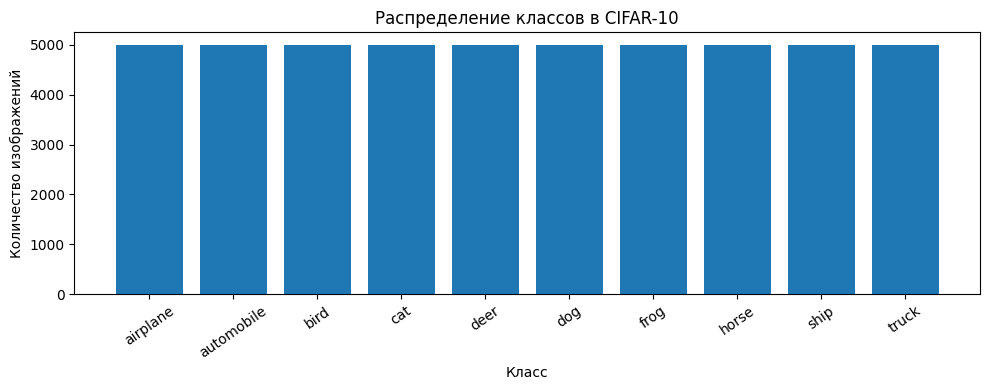

Количество изображений по классам:
    airplane: 5000
  automobile: 5000
        bird: 5000
         cat: 5000
        deer: 5000
         dog: 5000
        frog: 5000
       horse: 5000
        ship: 5000
       truck: 5000

Разница между максимальным и минимальным числом изображений: 0


In [9]:
train_labels = np.array(base_train.targets)
class_counts = np.bincount(train_labels, minlength=NUM_CLASSES)

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(CLASS_NAMES, class_counts)

ax.set_title("Распределение классов в CIFAR-10")
ax.set_xlabel("Класс")
ax.set_ylabel("Количество изображений")
ax.tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()

print("Количество изображений по классам:")
for name, count in zip(CLASS_NAMES, class_counts):
    print(f"{name:>12}: {count}")

print(
    "\nРазница между максимальным и минимальным числом изображений:",
    int(class_counts.max() - class_counts.min())
)

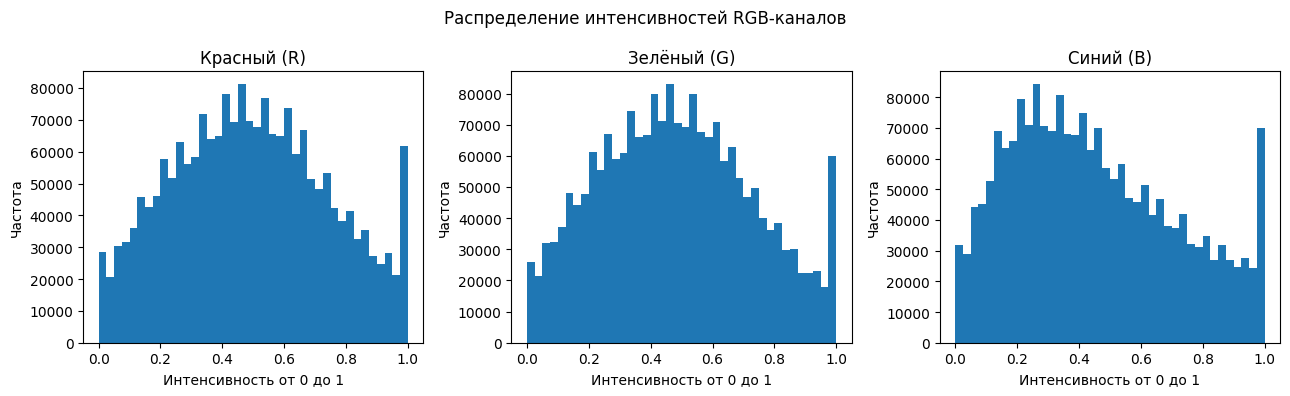

In [10]:
sample_ids = np.random.default_rng(SEED).choice(
    len(base_train),
    size=2000,
    replace=False
)

rgb_pixels = []

for idx in sample_ids:
    image = base_train.data[idx].astype(np.float32) / 255.0
    rgb_pixels.append(image.reshape(-1, 3))

rgb_pixels = np.concatenate(rgb_pixels, axis=0)

fig, axes = plt.subplots(1, 3, figsize=(13, 4))

for channel, ax, name in zip(
    range(3),
    axes,
    ["Красный (R)", "Зелёный (G)", "Синий (B)"]
):
    ax.hist(rgb_pixels[:, channel], bins=40)
    ax.set_title(name)
    ax.set_xlabel("Интенсивность от 0 до 1")
    ax.set_ylabel("Частота")

fig.suptitle("Распределение интенсивностей RGB-каналов")
plt.tight_layout()
plt.show()

## 2. Реализация собственной CNN

Собственная CNN строится из трёх свёрточных блоков. Каждый блок включает свёртку, Batch Normalization, ReLU и Max Pooling.

Для варианта 0:

- первый блок: 16 фильтров;
- второй блок: 32 фильтра;
- третий блок: 64 фильтра.

После свёрточных блоков применяется Global Average Pooling. Классификатор содержит два скрытых полносвязных слоя и выходной слой на 10 классов. Значение Dropout задаётся параметрами варианта.

In [19]:
class ConvBlock(nn.Module):
    """Conv2d -> BatchNorm2d -> ReLU -> MaxPool2d."""

    def __init__(self, in_channels, out_channels, kernel_size):
        super().__init__()

        self.conv = nn.Conv2d(
            in_channels,
            out_channels,
            kernel_size=kernel_size,
            padding=kernel_size // 2,
            bias=False
        )

        self.bn = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU(inplace=True)
        self.pool = nn.MaxPool2d(kernel_size=2)

    def forward(self, x):
        x = self.conv(x)
        x = self.bn(x)
        x = self.relu(x)
        x = self.pool(x)
        return x


class CustomCNN(nn.Module):

    def __init__(
        self,
        variant,
        in_channels,
        num_classes,
        input_size,
        dropout
    ):
        super().__init__()

        f1 = 16 * (variant + 1)
        f2 = f1 * 2
        f3 = f2 * 2

        k3 = max(
            1,
            min(variant + 2, input_size // 4)
        )

        self.features = nn.Sequential(
            ConvBlock(in_channels, f1, kernel_size=3),
            ConvBlock(f1, f2, kernel_size=3),
            ConvBlock(f2, f3, kernel_size=k3)
        )

        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(f3, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            nn.Linear(256, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.global_pool(x)
        x = self.classifier(x)
        return x


def count_parameters(model, trainable_only=False):
    if trainable_only:
        return sum(
            p.numel()
            for p in model.parameters()
            if p.requires_grad
        )

    return sum(p.numel() for p in model.parameters())


cnn_model = CustomCNN(
    variant=VARIANT,
    in_channels=3,
    num_classes=NUM_CLASSES,
    input_size=IMG_SIZE,
    dropout=DROPOUT
).to(DEVICE)

print(cnn_model)
print(f"Всего параметров: {count_parameters(cnn_model):,}")
print(
    "Обучаемых параметров:",
    f"{count_parameters(cnn_model, trainable_only=True):,}"
)

test_batch, _ = next(iter(train_loader))

with torch.no_grad():
    output = cnn_model(test_batch.to(DEVICE))

print("Размер входного батча:", tuple(test_batch.shape))
print("Размер выхода:", tuple(output.shape))

assert output.shape == (test_batch.shape[0], NUM_CLASSES)

CustomCNN(
  (features): Sequential(
    (0): ConvBlock(
      (conv): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): ConvBlock(
      (conv): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (2): ConvBlock(
      (conv): Conv2d(32, 64, kernel_size=(2, 2), stride=(1, 1), padding=(1, 1), bias=False)
      (bn): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dil

In [20]:
def run_epoch(model, loader, criterion, optimizer=None):

    training = optimizer is not None
    model.train(training)

    total_loss = 0.0
    y_true = []
    y_pred = []

    for x, y in loader:
        x = x.to(DEVICE)
        y = y.to(DEVICE)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            logits = model(x)
            loss = criterion(logits, y)

            if training:
                loss.backward()
                optimizer.step()

        total_loss += loss.item() * x.size(0)

        y_true.extend(y.detach().cpu().tolist())
        y_pred.extend(logits.argmax(dim=1).detach().cpu().tolist())

    return {
        "loss": total_loss / len(loader.dataset),
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )
    }


def fit_model(
    model,
    train_loader,
    val_loader,
    epochs,
    learning_rate,
    run_name
):
    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.Adam(
        [p for p in model.parameters() if p.requires_grad],
        lr=learning_rate
    )

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_accuracy": [],
        "val_accuracy": [],
        "train_macro_f1": [],
        "val_macro_f1": []
    }

    best_f1 = -1.0
    best_state = copy.deepcopy(model.state_dict())

    start_time = time.time()

    for epoch in range(1, epochs + 1):
        train_metrics = run_epoch(
            model,
            train_loader,
            criterion,
            optimizer
        )

        val_metrics = run_epoch(
            model,
            val_loader,
            criterion
        )

        for metric in ["loss", "accuracy", "macro_f1"]:
            history[f"train_{metric}"].append(
                train_metrics[metric]
            )
            history[f"val_{metric}"].append(
                val_metrics[metric]
            )

        if val_metrics["macro_f1"] > best_f1:
            best_f1 = val_metrics["macro_f1"]
            best_state = copy.deepcopy(model.state_dict())

        print(
            f"{run_name} | "
            f"эпоха {epoch:02d}/{epochs} | "
            f"train loss={train_metrics['loss']:.4f} | "
            f"train acc={train_metrics['accuracy']:.4f} | "
            f"train F1={train_metrics['macro_f1']:.4f} | "
            f"val loss={val_metrics['loss']:.4f} | "
            f"val acc={val_metrics['accuracy']:.4f} | "
            f"val F1={val_metrics['macro_f1']:.4f}"
        )

    elapsed = time.time() - start_time

    model.load_state_dict(best_state)

    print(
        f"\n{run_name}: обучение завершено за "
        f"{elapsed / 60:.2f} мин."
    )
    print(f"Лучший validation Macro-F1: {best_f1:.4f}")

    return model, history, elapsed


def plot_history(history, title):
    epochs = range(1, len(history["train_loss"]) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(
        epochs,
        history["train_loss"],
        marker="o",
        label="Train"
    )
    axes[0].plot(
        epochs,
        history["val_loss"],
        marker="o",
        label="Validation"
    )
    axes[0].set_title("Функция потерь")
    axes[0].set_xlabel("Эпоха")
    axes[0].set_ylabel("Cross-entropy loss")
    axes[0].legend()

    axes[1].plot(
        epochs,
        history["train_accuracy"],
        marker="o",
        label="Train"
    )
    axes[1].plot(
        epochs,
        history["val_accuracy"],
        marker="o",
        label="Validation"
    )
    axes[1].set_title("Accuracy")
    axes[1].set_xlabel("Эпоха")
    axes[1].set_ylabel("Accuracy")
    axes[1].legend()

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

Original CNN | эпоха 01/30 | train loss=1.7473 | train acc=0.3371 | train F1=0.3289 | val loss=1.4418 | val acc=0.4546 | val F1=0.4336
Original CNN | эпоха 02/30 | train loss=1.4613 | train acc=0.4607 | train F1=0.4547 | val loss=1.2904 | val acc=0.5406 | val F1=0.5443
Original CNN | эпоха 03/30 | train loss=1.3528 | train acc=0.5046 | train F1=0.4995 | val loss=1.1550 | val acc=0.5764 | val F1=0.5564
Original CNN | эпоха 04/30 | train loss=1.2870 | train acc=0.5313 | train F1=0.5275 | val loss=1.1218 | val acc=0.5890 | val F1=0.5815
Original CNN | эпоха 05/30 | train loss=1.2400 | train acc=0.5498 | train F1=0.5463 | val loss=1.0646 | val acc=0.6152 | val F1=0.6072
Original CNN | эпоха 06/30 | train loss=1.2111 | train acc=0.5616 | train F1=0.5587 | val loss=0.9969 | val acc=0.6464 | val F1=0.6431
Original CNN | эпоха 07/30 | train loss=1.1830 | train acc=0.5720 | train F1=0.5693 | val loss=1.0487 | val acc=0.6276 | val F1=0.6166
Original CNN | эпоха 08/30 | train loss=1.1543 | train 

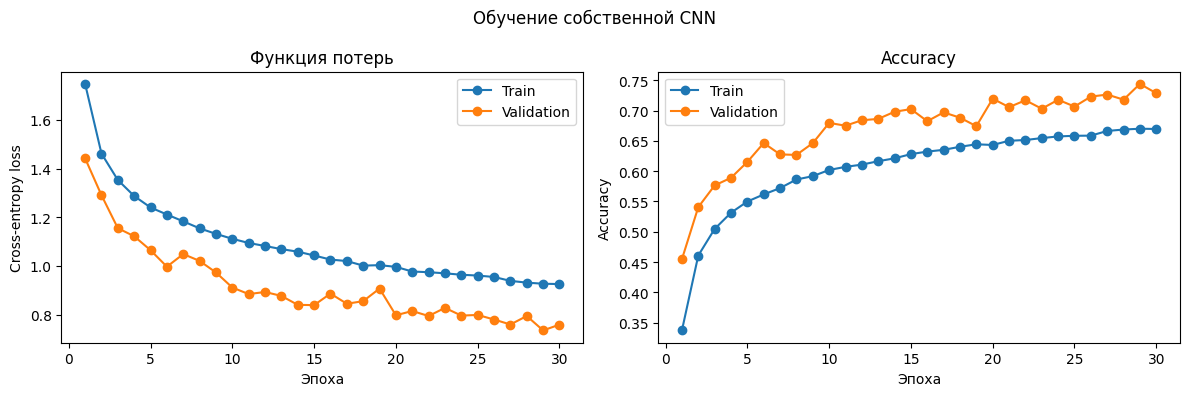

In [21]:
cnn_model, cnn_history, cnn_seconds = fit_model(
    model=cnn_model,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=EPOCHS,
    learning_rate=LEARNING_RATE,
    run_name="Original CNN"
)

plot_history(
    cnn_history,
    "Обучение собственной CNN"
)

## 3. Transfer learning с MobileNetV2

Для сравнения используется предобученная MobileNetV2 из библиотеки `timm`.

Обучение проводится в два этапа:

1. Backbone замораживается, обучается только новая классификационная голова в течение пяти эпох с learning rate `1e-3`.
2. Размораживается последний блок backbone и выполняется fine-tuning с меньшим learning rate.


In [22]:
class TransferModel(nn.Module):
    def __init__(
        self,
        backbone_name=BACKBONE_NAME,
        num_classes=NUM_CLASSES,
        pretrained=True
    ):
        super().__init__()

        self.backbone = timm.create_model(
            backbone_name,
            pretrained=pretrained,
            num_classes=0
        )

        feat_dim = self.backbone.num_features

        self.head = nn.Sequential(
            nn.Linear(feat_dim, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.1 * VARIANT),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        features = self.backbone(x)
        return self.head(features)


def freeze_backbone(model):
    for parameter in model.backbone.parameters():
        parameter.requires_grad = False


def unfreeze_last_blocks(model, n_blocks=1):
    """Размораживает последние n блоков backbone."""
    for parameter in model.backbone.parameters():
        parameter.requires_grad = False

    blocks = getattr(model.backbone, "blocks", None)

    if blocks is None:
        raise AttributeError(
            "У выбранного backbone не найден атрибут blocks."
        )

    for block in list(blocks.children())[-n_blocks:]:
        for parameter in block.parameters():
            parameter.requires_grad = True

    return model


transfer_model = TransferModel().to(DEVICE)
freeze_backbone(transfer_model)

print("Transfer-модель:")
print(transfer_model)
print(
    "Всего параметров:",
    f"{count_parameters(transfer_model):,}"
)
print(
    "Обучаемых параметров до fine-tuning:",
    f"{count_parameters(transfer_model, True):,}"
)

model.safetensors: reconstructing file:   0%|          |  0.00B / 14.2MB            

model.safetensors: downloading bytes:           |  0.00B            

Transfer-модель:
TransferModel(
  (backbone): EfficientNet(
    (conv_stem): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
    (bn1): BatchNormAct2d(
      32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True
      (drop): Identity()
      (act): ReLU6(inplace=True)
    )
    (blocks): Sequential(
      (0): Sequential(
        (0): DepthwiseSeparableConv(
          (conv_dw): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
          (bn1): BatchNormAct2d(
            32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True
            (drop): Identity()
            (act): ReLU6(inplace=True)
          )
          (aa): Identity()
          (se): Identity()
          (conv_pw): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn2): BatchNormAct2d(
            16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True
            (drop): Identity()
            

MobileNetV2: обучение головы | эпоха 01/5 | train loss=1.9054 | train acc=0.3262 | train F1=0.3237 | val loss=1.7006 | val acc=0.4102 | val F1=0.3994
MobileNetV2: обучение головы | эпоха 02/5 | train loss=1.8271 | train acc=0.3492 | train F1=0.3462 | val loss=1.6400 | val acc=0.4218 | val F1=0.4154
MobileNetV2: обучение головы | эпоха 03/5 | train loss=1.8053 | train acc=0.3566 | train F1=0.3543 | val loss=1.6350 | val acc=0.4166 | val F1=0.4146
MobileNetV2: обучение головы | эпоха 04/5 | train loss=1.8084 | train acc=0.3565 | train F1=0.3539 | val loss=1.6052 | val acc=0.4294 | val F1=0.4264
MobileNetV2: обучение головы | эпоха 05/5 | train loss=1.8018 | train acc=0.3533 | train F1=0.3507 | val loss=1.6268 | val acc=0.4292 | val F1=0.4249

MobileNetV2: обучение головы: обучение завершено за 11.64 мин.
Лучший validation Macro-F1: 0.4264


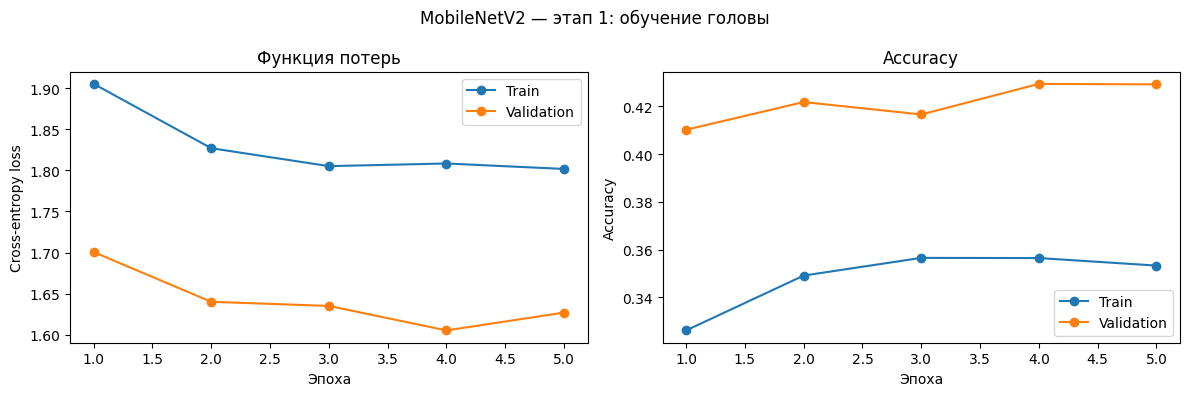

In [23]:
transfer_model, head_history, head_seconds = fit_model(
    model=transfer_model,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=HEAD_EPOCHS,
    learning_rate=HEAD_LR,
    run_name="MobileNetV2: обучение головы"
)

plot_history(
    head_history,
    "MobileNetV2 — этап 1: обучение головы"
)

Обучаемых параметров после размораживания: 804,426
MobileNetV2: fine-tuning | эпоха 01/5 | train loss=1.7459 | train acc=0.3804 | train F1=0.3777 | val loss=1.5322 | val acc=0.4536 | val F1=0.4479
MobileNetV2: fine-tuning | эпоха 02/5 | train loss=1.7017 | train acc=0.3950 | train F1=0.3924 | val loss=1.4658 | val acc=0.4772 | val F1=0.4718
MobileNetV2: fine-tuning | эпоха 03/5 | train loss=1.6627 | train acc=0.4050 | train F1=0.4026 | val loss=1.4415 | val acc=0.4928 | val F1=0.4897
MobileNetV2: fine-tuning | эпоха 04/5 | train loss=1.6465 | train acc=0.4140 | train F1=0.4122 | val loss=1.4357 | val acc=0.4974 | val F1=0.4944
MobileNetV2: fine-tuning | эпоха 05/5 | train loss=1.6284 | train acc=0.4239 | train F1=0.4219 | val loss=1.4108 | val acc=0.4978 | val F1=0.4939

MobileNetV2: fine-tuning: обучение завершено за 14.60 мин.
Лучший validation Macro-F1: 0.4944


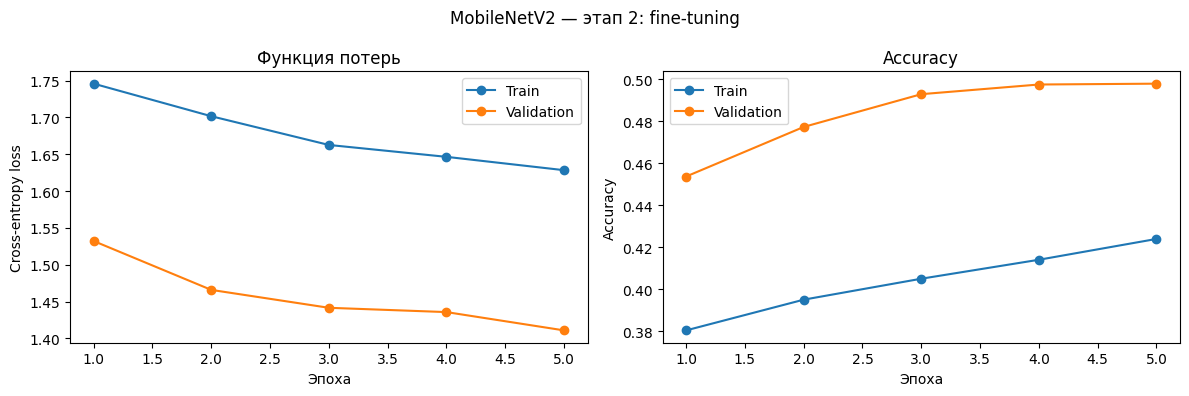

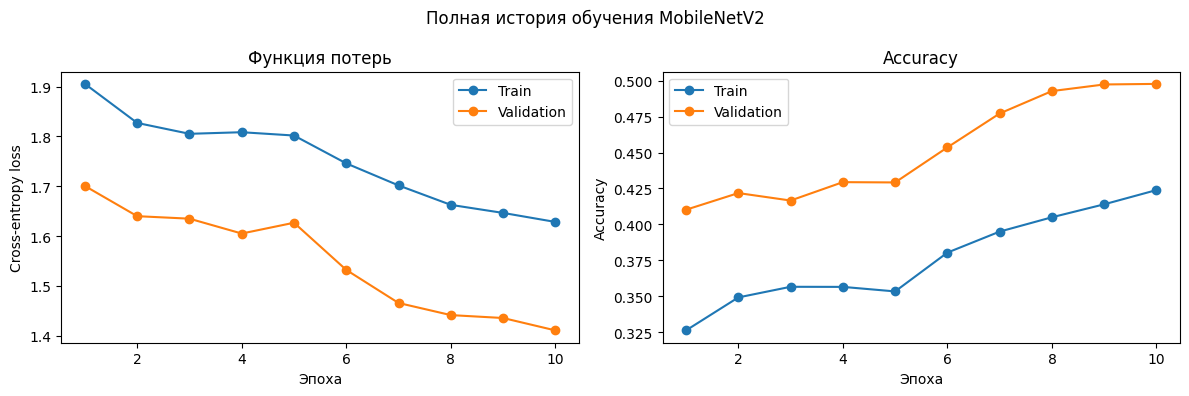

In [24]:
transfer_model = unfreeze_last_blocks(
    transfer_model,
    n_blocks=N_UNFREEZE
).to(DEVICE)

print(
    "Обучаемых параметров после размораживания:",
    f"{count_parameters(transfer_model, True):,}"
)

transfer_model, fine_history, fine_seconds = fit_model(
    model=transfer_model,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=FINE_EPOCHS,
    learning_rate=FINE_LR,
    run_name="MobileNetV2: fine-tuning"
)

plot_history(
    fine_history,
    "MobileNetV2 — этап 2: fine-tuning"
)

transfer_history = {
    key: head_history[key] + fine_history[key]
    for key in head_history
}

plot_history(
    transfer_history,
    "Полная история обучения MobileNetV2"
)

## 4. Оценка качества моделей

Для обеих моделей рассчитываются Accuracy и Macro-F1 на тестовой выборке. При этом тестовые данные не используются для обучения и выбора лучшей эпохи: выбор состояния моделей осуществляется по валидационному Macro-F1.

Дополнительно рассчитываются число параметров и время обучения. Для модели с лучшим тестовым Macro-F1 строится матрица ошибок.

In [25]:
@torch.no_grad()
def predict_all(model, loader):
    model.eval()

    y_true = []
    y_pred = []
    probabilities = []

    for x, y in loader:
        logits = model(x.to(DEVICE))
        probs = torch.softmax(logits, dim=1)

        y_true.extend(y.tolist())
        y_pred.extend(
            logits.argmax(dim=1).cpu().tolist()
        )
        probabilities.extend(probs.cpu().numpy())

    return (
        np.asarray(y_true),
        np.asarray(y_pred),
        np.asarray(probabilities)
    )


def evaluate_model(model, loader, model_name, training_seconds):
    y_true, y_pred, probabilities = predict_all(
        model,
        loader
    )

    metrics = {
        "Модель": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro-F1": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),
        "Параметры": count_parameters(model),
        "Время обучения, сек.": training_seconds
    }

    return metrics, y_true, y_pred, probabilities


cnn_metrics, y_true_cnn, y_pred_cnn, prob_cnn = evaluate_model(
    cnn_model,
    test_loader,
    "Original CNN",
    cnn_seconds
)

transfer_metrics, y_true_tl, y_pred_tl, prob_tl = evaluate_model(
    transfer_model,
    test_loader,
    "MobileNetV2",
    head_seconds + fine_seconds
)

comparison = pd.DataFrame([
    cnn_metrics,
    transfer_metrics
])

display(comparison.round(4))

,Модель,Accuracy,Macro-F1,Параметры,"Время обучения, сек."
0,Original CNN,0.7317,0.7294,64282,2834.5947
1,MobileNetV2,0.4845,0.4827,2554378,1574.6438


In [26]:
print("Classification report — Original CNN")
print(
    classification_report(
        y_true_cnn,
        y_pred_cnn,
        labels=list(range(NUM_CLASSES)),
        target_names=CLASS_NAMES,
        zero_division=0
    )
)

print("\nClassification report — MobileNetV2")
print(
    classification_report(
        y_true_tl,
        y_pred_tl,
        labels=list(range(NUM_CLASSES)),
        target_names=CLASS_NAMES,
        zero_division=0
    )
)

Classification report — Original CNN
              precision    recall  f1-score   support

    airplane       0.70      0.81      0.75      1000
  automobile       0.87      0.86      0.87      1000
        bird       0.59      0.67      0.63      1000
         cat       0.64      0.46      0.53      1000
        deer       0.65      0.70      0.67      1000
         dog       0.66      0.60      0.63      1000
        frog       0.77      0.78      0.77      1000
       horse       0.76      0.77      0.76      1000
        ship       0.86      0.83      0.85      1000
       truck       0.83      0.84      0.84      1000

    accuracy                           0.73     10000
   macro avg       0.73      0.73      0.73     10000
weighted avg       0.73      0.73      0.73     10000


Classification report — MobileNetV2
              precision    recall  f1-score   support

    airplane       0.52      0.58      0.55      1000
  automobile       0.56      0.53      0.54      1000
    

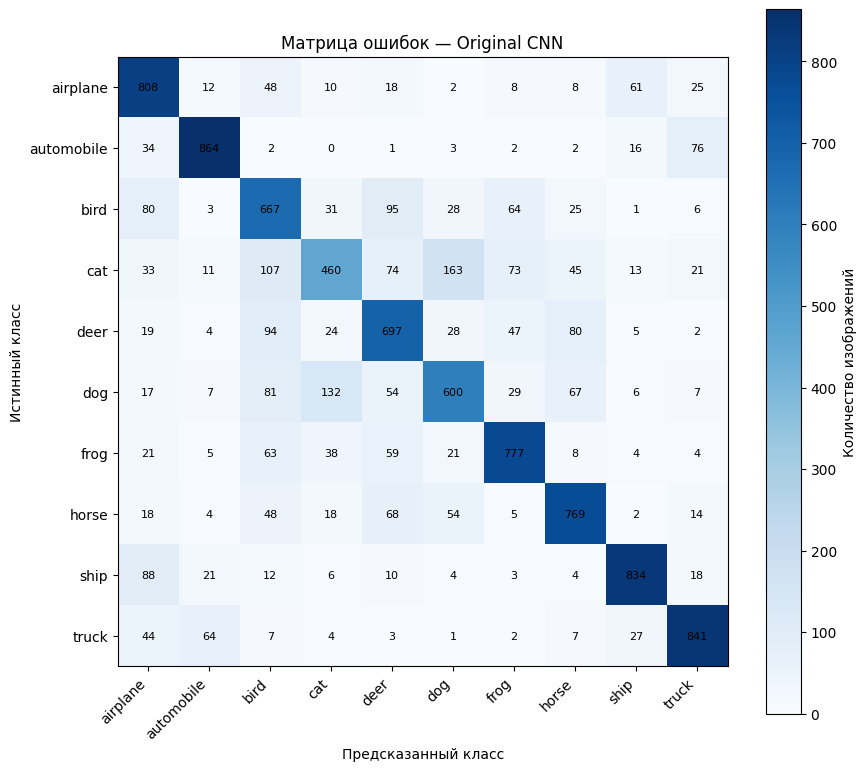

In [27]:
if transfer_metrics["Macro-F1"] >= cnn_metrics["Macro-F1"]:
    best_model = transfer_model
    best_name = "MobileNetV2"
    y_true_best = y_true_tl
    y_pred_best = y_pred_tl
else:
    best_model = cnn_model
    best_name = "Original CNN"
    y_true_best = y_true_cnn
    y_pred_best = y_pred_cnn

cm = confusion_matrix(
    y_true_best,
    y_pred_best,
    labels=list(range(NUM_CLASSES))
)

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(cm, cmap="Blues")

ax.set_title(f"Матрица ошибок — {best_name}")
ax.set_xlabel("Предсказанный класс")
ax.set_ylabel("Истинный класс")
ax.set_xticks(
    range(NUM_CLASSES),
    CLASS_NAMES,
    rotation=45,
    ha="right"
)
ax.set_yticks(range(NUM_CLASSES), CLASS_NAMES)

for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        ax.text(
            j,
            i,
            str(cm[i, j]),
            ha="center",
            va="center",
            fontsize=8
        )

fig.colorbar(im, ax=ax, label="Количество изображений")
plt.tight_layout()
plt.show()

In [28]:
cm_errors = cm.copy()
np.fill_diagonal(cm_errors, 0)

sorted_indices = np.argsort(
    cm_errors.ravel()
)[::-1]

print("Наиболее частые путаницы классов:")

shown = 0

for flat_index in sorted_indices:
    i, j = np.unravel_index(flat_index, cm_errors.shape)
    count = int(cm_errors[i, j])

    if count == 0:
        break

    print(
        f"{CLASS_NAMES[i]} → {CLASS_NAMES[j]}: "
        f"{count} изображений"
    )

    shown += 1
    if shown == 10:
        break

Наиболее частые путаницы классов:
cat → dog: 163 изображений
dog → cat: 132 изображений
cat → bird: 107 изображений
bird → deer: 95 изображений
deer → bird: 94 изображений
ship → airplane: 88 изображений
dog → bird: 81 изображений
bird → airplane: 80 изображений
deer → horse: 80 изображений
automobile → truck: 76 изображений


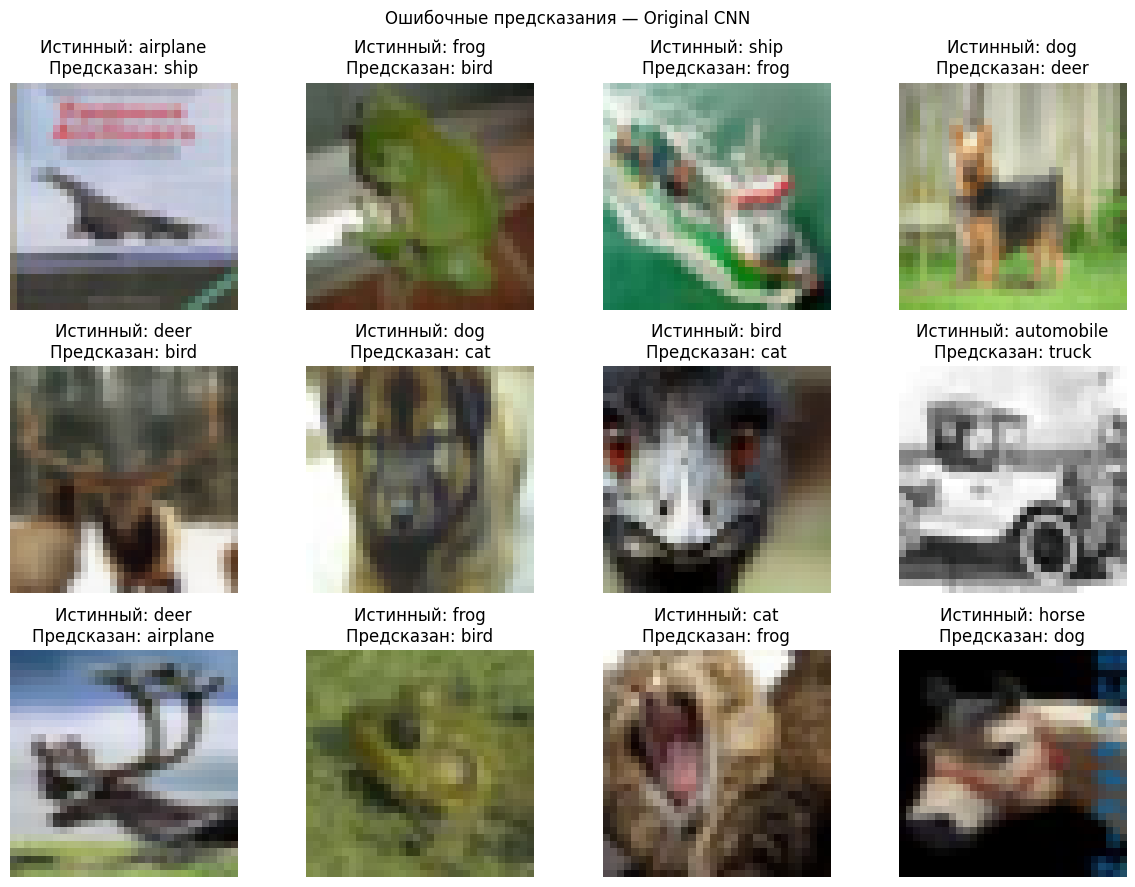

Показано 12 ошибок из 2683.


In [29]:
def show_misclassified(model, dataset, max_images=12):
    loader = DataLoader(
        dataset,
        batch_size=128,
        shuffle=False,
        num_workers=0
    )

    y_true, y_pred, _ = predict_all(model, loader)
    error_indices = np.flatnonzero(y_true != y_pred)

    if len(error_indices) == 0:
        print("Ошибочных предсказаний не найдено.")
        return

    chosen = error_indices[:max_images]

    cols = 4
    rows = int(np.ceil(len(chosen) / cols))

    fig, axes = plt.subplots(
        rows,
        cols,
        figsize=(12, 3 * rows)
    )

    axes = np.asarray(axes).reshape(-1)

    for ax, idx in zip(axes, chosen):
        image, label = dataset[int(idx)]

        image_vis = denormalize(
            image.unsqueeze(0)
        )[0].permute(1, 2, 0).numpy()

        ax.imshow(image_vis)
        ax.set_title(
            f"Истинный: {CLASS_NAMES[int(label)]}\n"
            f"Предсказан: {CLASS_NAMES[int(y_pred[idx])]}"
        )
        ax.axis("off")

    for ax in axes[len(chosen):]:
        ax.axis("off")

    fig.suptitle(
        f"Ошибочные предсказания — {best_name}"
    )
    plt.tight_layout()
    plt.show()

    print(
        f"Показано {len(chosen)} ошибок "
        f"из {len(error_indices)}."
    )


show_misclassified(
    best_model,
    test_ds,
    max_images=12
)

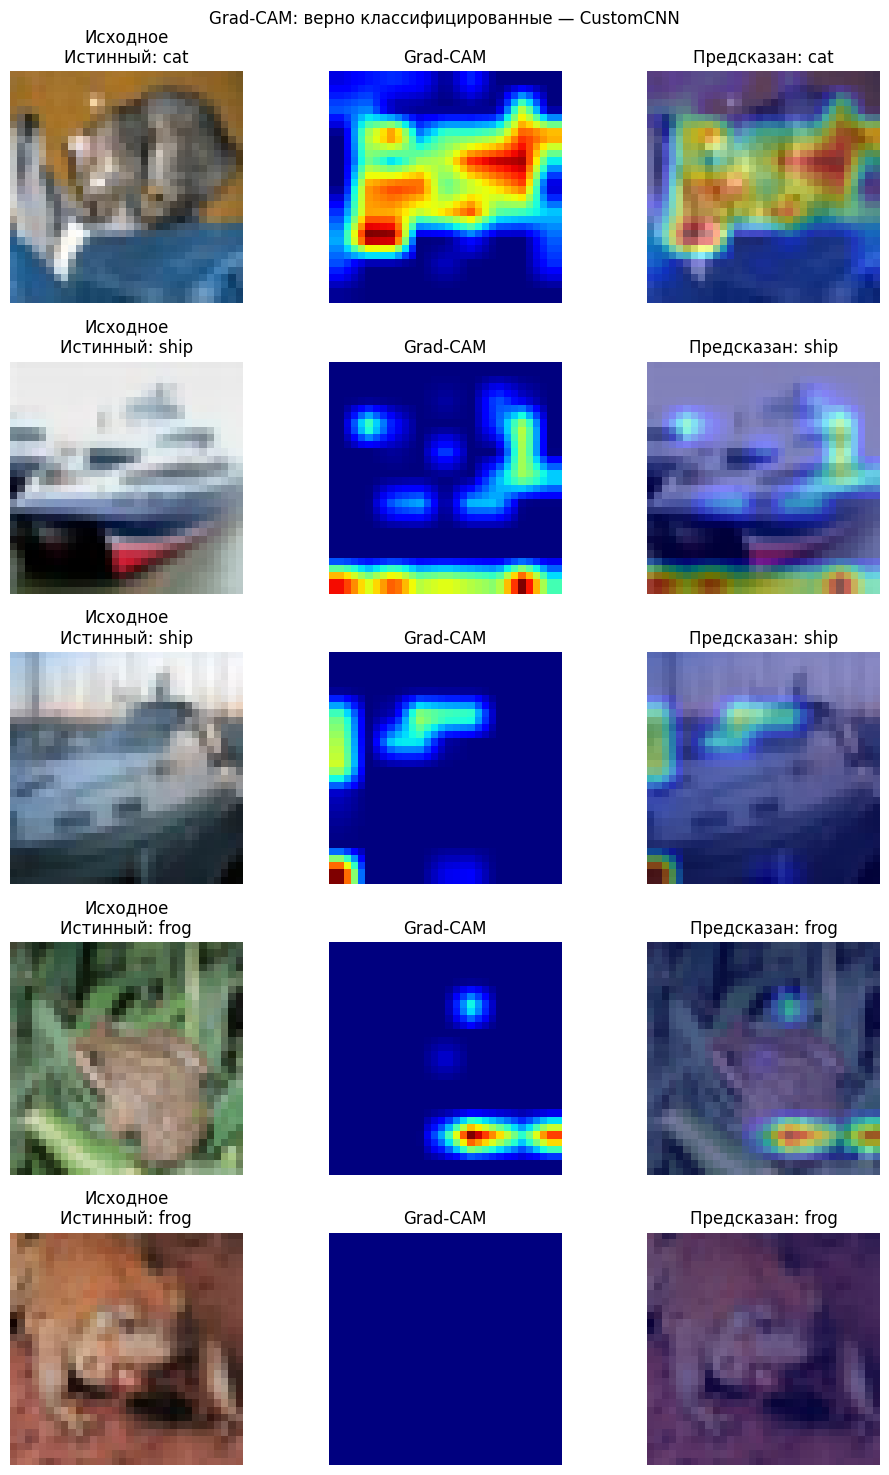

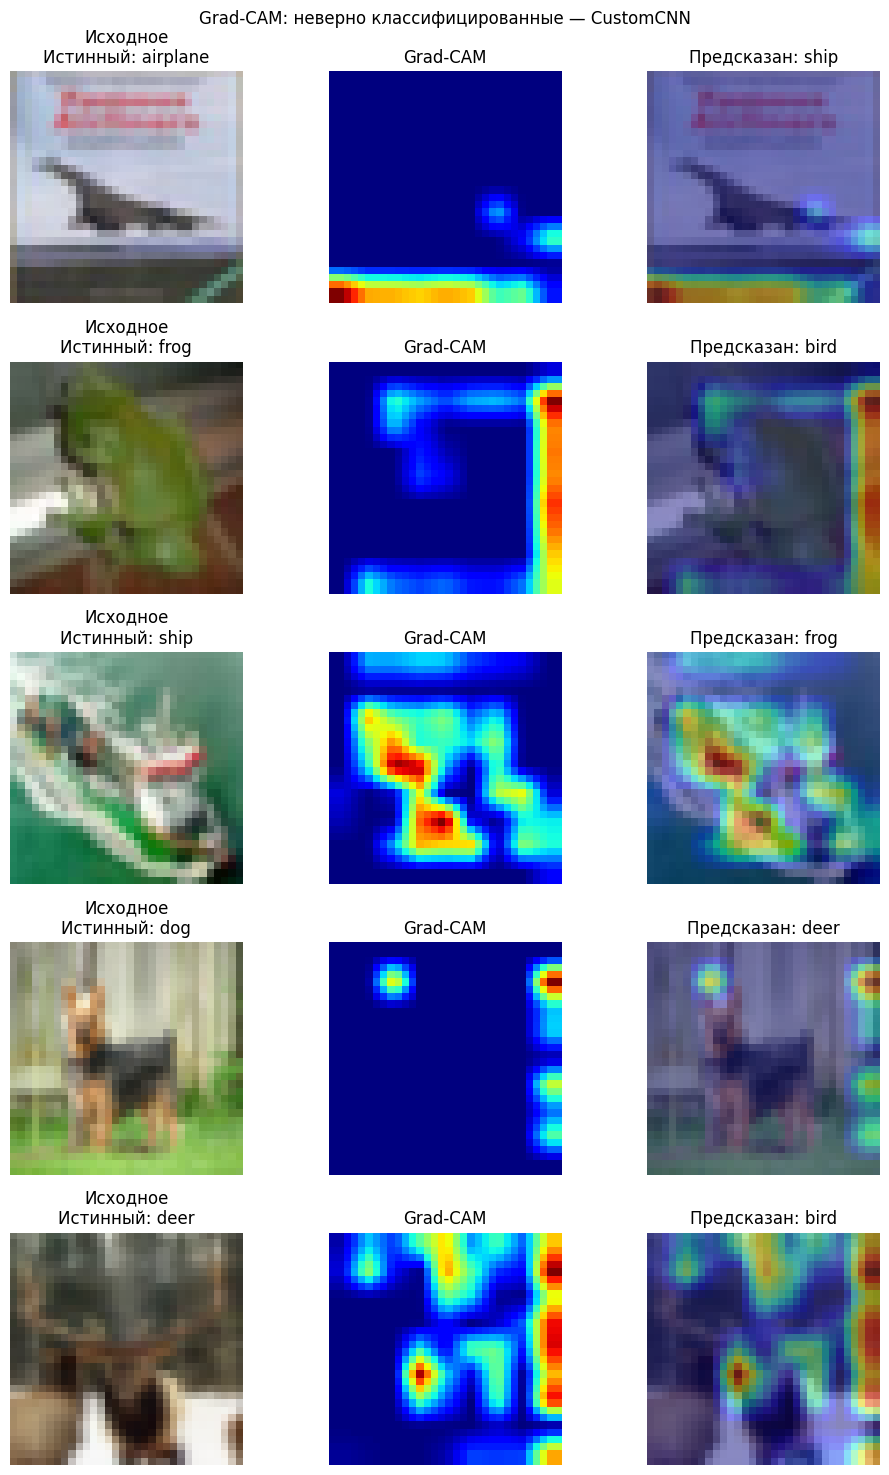

In [ ]:
def get_target_layer(model):
    if isinstance(model, CustomCNN):
        return model.features[-1].conv

    if isinstance(model, TransferModel):
        return model.backbone.blocks[-1]

    raise TypeError("Неизвестный тип модели.")


def grad_cam(model, image_tensor, class_index=None):
    
    model.eval()

    target_layer = get_target_layer(model)
    saved = {}

    def forward_hook(module, inputs, output):
        saved["activations"] = output

        output.register_hook(
            lambda grad: saved.__setitem__("gradients", grad)
        )

    handle = target_layer.register_forward_hook(forward_hook)

    model.zero_grad(set_to_none=True)

    x = image_tensor.unsqueeze(0).to(DEVICE)
    logits = model(x)

    if class_index is None:
        class_index = int(logits.argmax(dim=1).item())

    score = logits[0, class_index]
    score.backward()

    activations = saved["activations"].detach()
    gradients = saved["gradients"].detach()

    weights = gradients.mean(
        dim=(2, 3),
        keepdim=True
    )

    cam = torch.relu(
        (weights * activations).sum(dim=1, keepdim=True)
    )

    cam = F.interpolate(
        cam,
        size=(IMG_SIZE, IMG_SIZE),
        mode="bilinear",
        align_corners=False
    )

    cam = cam[0, 0].cpu().numpy()
    cam = (
        (cam - cam.min()) /
        (cam.max() - cam.min() + 1e-8)
    )

    handle.remove()
    model.zero_grad(set_to_none=True)

    return cam, class_index


def show_gradcam_examples(model, dataset, correct=True, n=5):
    loader = DataLoader(
        dataset,
        batch_size=128,
        shuffle=False,
        num_workers=0
    )

    y_true, y_pred, _ = predict_all(model, loader)

    if correct:
        candidates = np.flatnonzero(y_true == y_pred)
        category = "верно классифицированные"
    else:
        candidates = np.flatnonzero(y_true != y_pred)
        category = "неверно классифицированные"

    if len(candidates) == 0:
        print(f"Нет примеров: {category}.")
        return

    chosen = candidates[:n]

    fig, axes = plt.subplots(
        len(chosen),
        3,
        figsize=(10, 3 * len(chosen))
    )

    if len(chosen) == 1:
        axes = np.expand_dims(axes, axis=0)

    for row, idx in enumerate(chosen):
        image, label = dataset[int(idx)]

        cam, predicted_class = grad_cam(
            model,
            image,
            class_index=int(y_pred[idx])
        )

        original = denormalize(
            image.unsqueeze(0)
        )[0].permute(1, 2, 0).numpy()

        axes[row, 0].imshow(original)
        axes[row, 0].set_title(
            f"Исходное\nИстинный: {CLASS_NAMES[int(label)]}"
        )

        axes[row, 1].imshow(cam, cmap="jet", vmin=0, vmax=1)
        axes[row, 1].set_title("Grad-CAM")

        axes[row, 2].imshow(original)
        axes[row, 2].imshow(
            cam,
            cmap="jet",
            alpha=0.45,
            vmin=0,
            vmax=1
        )
        axes[row, 2].set_title(
            f"Предсказан: {CLASS_NAMES[predicted_class]}"
        )

        for ax in axes[row]:
            ax.axis("off")

    fig.suptitle(
        f"Grad-CAM: {category} — {type(model).__name__}"
    )
    plt.tight_layout()
    plt.show()


show_gradcam_examples(
    best_model,
    test_ds,
    correct=True,
    n=5
)

show_gradcam_examples(
    best_model,
    test_ds,
    correct=False,
    n=5
)

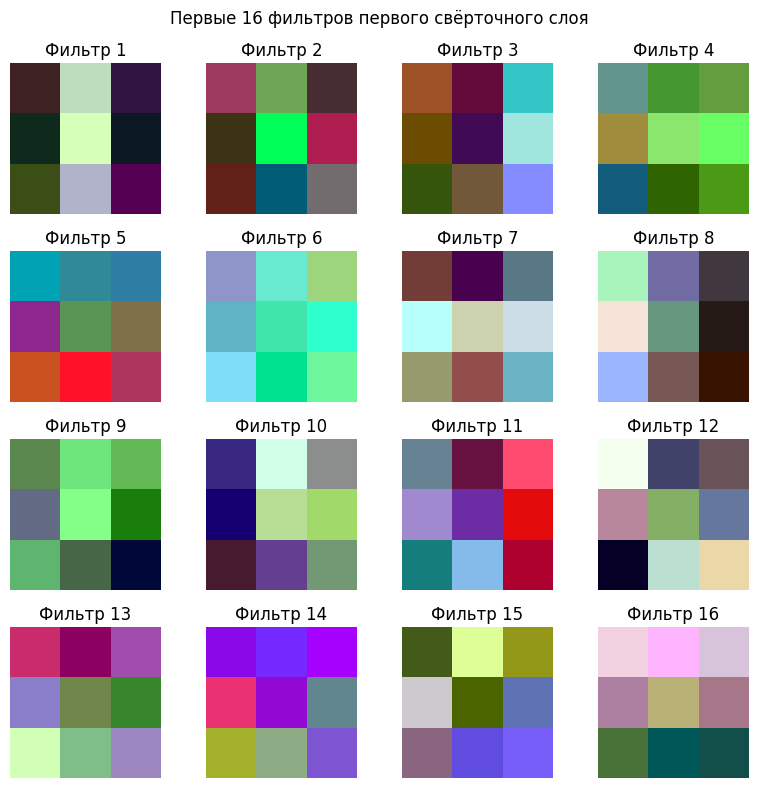

In [ ]:
first_conv = cnn_model.features[0].conv
filters = first_conv.weight.detach().cpu()

fig, axes = plt.subplots(4, 4, figsize=(8, 8))

for i, ax in enumerate(axes.flat):
    filt = filters[i]

    filt = filt - filt.min()
    filt = filt / (filt.max() + 1e-8)

    ax.imshow(
        filt.permute(1, 2, 0).numpy()
    )
    ax.set_title(f"Фильтр {i + 1}")
    ax.axis("off")

fig.suptitle(
    "Первые 16 фильтров первого свёрточного слоя"
)
plt.tight_layout()
plt.show()

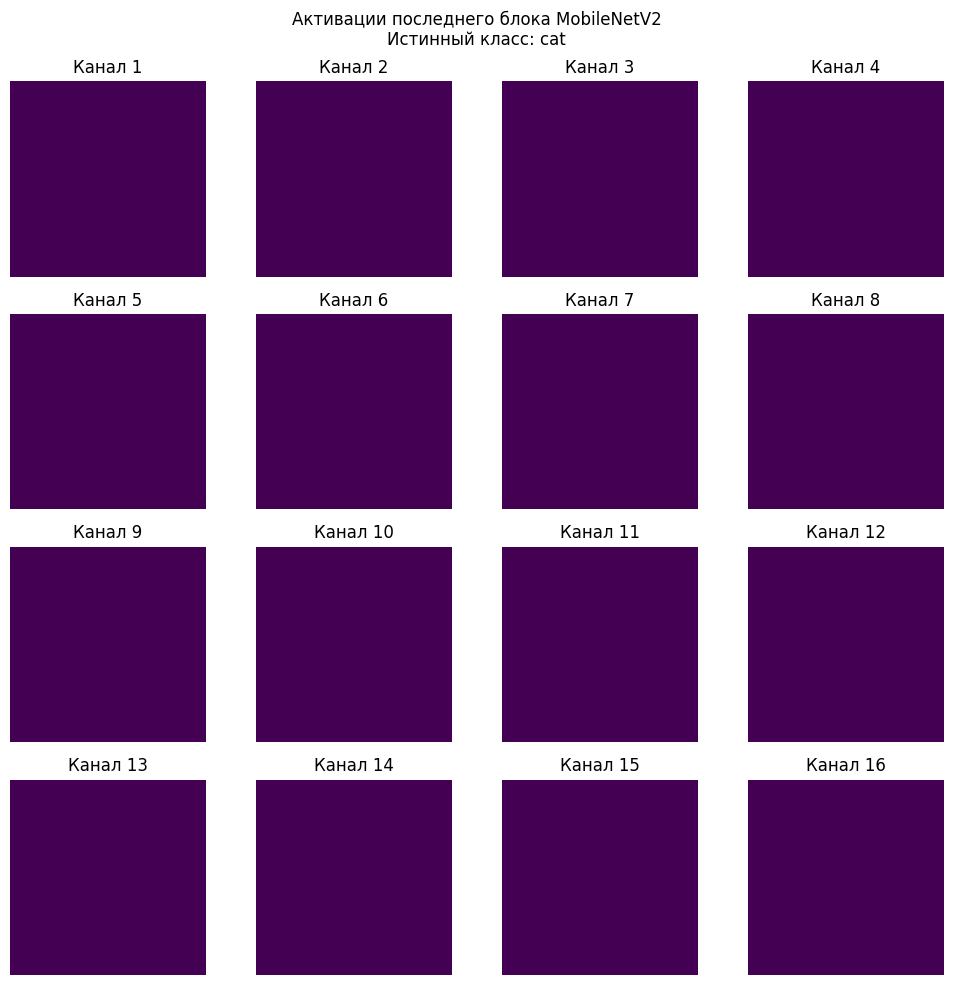

In [32]:
def show_backbone_activations(
    model,
    dataset,
    sample_index=0,
    max_channels=16
):
    model.eval()

    captured = {}
    target_layer = model.backbone.blocks[-1]

    def activation_hook(module, inputs, output):
        captured["activation"] = output.detach().cpu()

    handle = target_layer.register_forward_hook(
        activation_hook
    )

    image, label = dataset[sample_index]

    with torch.no_grad():
        _ = model(image.unsqueeze(0).to(DEVICE))

    handle.remove()

    activation = captured["activation"][0]
    n_channels = min(
        max_channels,
        activation.shape[0]
    )

    cols = 4
    rows = int(np.ceil(n_channels / cols))

    fig, axes = plt.subplots(
        rows,
        cols,
        figsize=(10, 2.5 * rows)
    )

    axes = np.asarray(axes).reshape(-1)

    for i in range(n_channels):
        axes[i].imshow(
            activation[i].numpy(),
            cmap="viridis"
        )
        axes[i].set_title(f"Канал {i + 1}")
        axes[i].axis("off")

    for ax in axes[n_channels:]:
        ax.axis("off")

    fig.suptitle(
        "Активации последнего блока MobileNetV2\n"
        f"Истинный класс: {CLASS_NAMES[int(label)]}"
    )

    plt.tight_layout()
    plt.show()


show_backbone_activations(
    transfer_model,
    test_ds,
    sample_index=0
)

## 5. Дополнительный эксперимент: MixUp


MixUp | эпоха 01/30 | train loss=1.8594 | train acc=0.2208 | val loss=1.3884 | val acc=0.4800 | val F1=0.4557
MixUp | эпоха 02/30 | train loss=1.6386 | train acc=0.2873 | val loss=1.3053 | val acc=0.5310 | val F1=0.5098
MixUp | эпоха 03/30 | train loss=1.5403 | train acc=0.3014 | val loss=1.1574 | val acc=0.5808 | val F1=0.5703
MixUp | эпоха 04/30 | train loss=1.4976 | train acc=0.3246 | val loss=1.1044 | val acc=0.6018 | val F1=0.5837
MixUp | эпоха 05/30 | train loss=1.4517 | train acc=0.3278 | val loss=1.0307 | val acc=0.6330 | val F1=0.6262
MixUp | эпоха 06/30 | train loss=1.4344 | train acc=0.3307 | val loss=1.1153 | val acc=0.5930 | val F1=0.5750
MixUp | эпоха 07/30 | train loss=1.4168 | train acc=0.3411 | val loss=0.9854 | val acc=0.6440 | val F1=0.6402
MixUp | эпоха 08/30 | train loss=1.3826 | train acc=0.3561 | val loss=0.9599 | val acc=0.6682 | val F1=0.6607
MixUp | эпоха 09/30 | train loss=1.3804 | train acc=0.3452 | val loss=0.9700 | val acc=0.6500 | val F1=0.6339
MixUp | эп

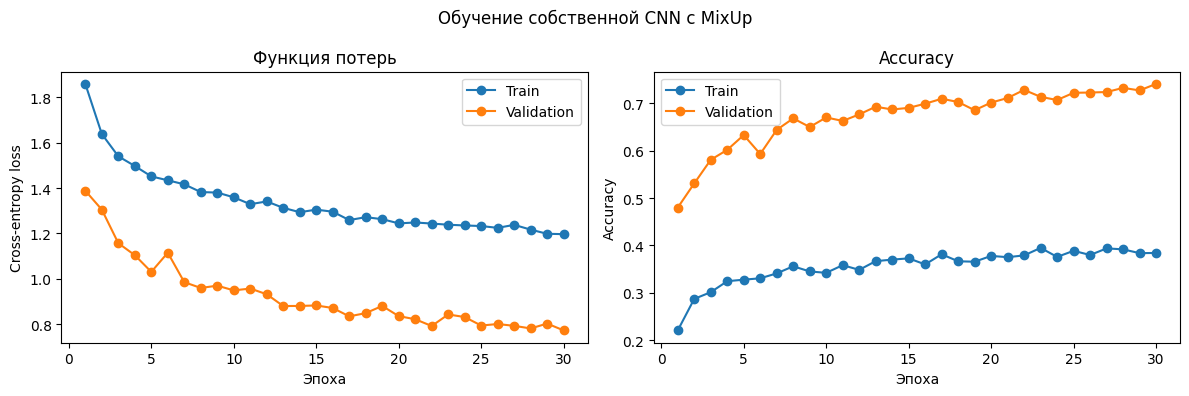

In [ ]:
def mixup_batch(x, y, alpha=0.2):
    lam = float(np.random.beta(alpha, alpha))

    permutation = torch.randperm(
        x.size(0),
        device=x.device
    )

    mixed_x = (
        lam * x
        + (1.0 - lam) * x[permutation]
    )

    y_a = y
    y_b = y[permutation]

    return mixed_x, y_a, y_b, lam


def fit_model_mixup(
    model,
    train_loader,
    val_loader,
    epochs,
    learning_rate,
    alpha=0.2
):
    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate
    )

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_accuracy": [],
        "val_accuracy": [],
        "train_macro_f1": [],
        "val_macro_f1": []
    }

    best_f1 = -1.0
    best_state = copy.deepcopy(model.state_dict())
    start_time = time.time()

    for epoch in range(1, epochs + 1):
        model.train()

        total_loss = 0.0
        train_true = []
        train_pred = []

        for x, y in train_loader:
            x = x.to(DEVICE)
            y = y.to(DEVICE)

            x_mix, y_a, y_b, lam = mixup_batch(
                x,
                y,
                alpha=alpha
            )

            optimizer.zero_grad(set_to_none=True)

            logits = model(x_mix)

            loss = (
                lam * criterion(logits, y_a)
                + (1.0 - lam) * criterion(logits, y_b)
            )

            loss.backward()
            optimizer.step()

            total_loss += loss.item() * x.size(0)

            train_true.extend(y.cpu().tolist())
            train_pred.extend(
                logits.argmax(dim=1).detach().cpu().tolist()
            )

        train_metrics = {
            "loss": total_loss / len(train_loader.dataset),
            "accuracy": accuracy_score(
                train_true,
                train_pred
            ),
            "macro_f1": f1_score(
                train_true,
                train_pred,
                average="macro",
                zero_division=0
            )
        }

        val_metrics = run_epoch(
            model,
            val_loader,
            criterion
        )

        for metric in ["loss", "accuracy", "macro_f1"]:
            history[f"train_{metric}"].append(
                train_metrics[metric]
            )
            history[f"val_{metric}"].append(
                val_metrics[metric]
            )

        if val_metrics["macro_f1"] > best_f1:
            best_f1 = val_metrics["macro_f1"]
            best_state = copy.deepcopy(model.state_dict())

        print(
            f"MixUp | эпоха {epoch:02d}/{epochs} | "
            f"train loss={train_metrics['loss']:.4f} | "
            f"train acc={train_metrics['accuracy']:.4f} | "
            f"val loss={val_metrics['loss']:.4f} | "
            f"val acc={val_metrics['accuracy']:.4f} | "
            f"val F1={val_metrics['macro_f1']:.4f}"
        )

    elapsed = time.time() - start_time
    model.load_state_dict(best_state)

    print(
        f"MixUp: время обучения {elapsed / 60:.2f} мин."
    )

    return model, history, elapsed

mixup_model = CustomCNN(
    variant=VARIANT,
    in_channels=3,
    num_classes=NUM_CLASSES,
    input_size=IMG_SIZE,
    dropout=DROPOUT
).to(DEVICE)

mixup_model, mixup_history, mixup_seconds = fit_model_mixup(
    model=mixup_model,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=EPOCHS,
    learning_rate=LEARNING_RATE,
    alpha=0.2
)

plot_history(
    mixup_history,
    "Обучение собственной CNN с MixUp"
)

In [34]:
mixup_metrics, y_true_mix, y_pred_mix, prob_mix = evaluate_model(
    mixup_model,
    test_loader,
    "Original CNN + MixUp",
    mixup_seconds
)

bonus_comparison = pd.DataFrame([
    cnn_metrics,
    mixup_metrics
])

display(bonus_comparison.round(4))

accuracy_difference = (
    mixup_metrics["Accuracy"] - cnn_metrics["Accuracy"]
)

f1_difference = (
    mixup_metrics["Macro-F1"] - cnn_metrics["Macro-F1"]
)

print(f"Изменение Accuracy: {accuracy_difference:+.4f}")
print(f"Изменение Macro-F1: {f1_difference:+.4f}")

if f1_difference > 0:
    print(
        "В данном эксперименте MixUp повысил Macro-F1."
    )
elif f1_difference < 0:
    print(
        "В данном эксперименте MixUp снизил Macro-F1."
    )
else:
    print(
        "В данном эксперименте Macro-F1 не изменился."
    )

,Модель,Accuracy,Macro-F1,Параметры,"Время обучения, сек."
0,Original CNN,0.7317,0.7294,64282,2834.5947
1,Original CNN + MixUp,0.7350,0.7329,64282,3006.5133


Изменение Accuracy: +0.0033
Изменение Macro-F1: +0.0036
В данном эксперименте MixUp повысил Macro-F1.


## 6. Сохранение модели и воспроизводимость


In [35]:
candidates = [
    (
        max(cnn_history["val_macro_f1"]),
        "original_cnn",
        cnn_model
    ),
    (
        max(transfer_history["val_macro_f1"]),
        "timm_transfer",
        transfer_model
    ),
    (
        max(mixup_history["val_macro_f1"]),
        "original_cnn_mixup",
        mixup_model
    )
]

best_val_f1, best_arch, artifact_model = max(
    candidates,
    key=lambda item: item[0]
)

checkpoint = {
    "model_state": artifact_model.state_dict(),
    "arch": best_arch,
    "backbone": (
        BACKBONE_NAME
        if best_arch == "timm_transfer"
        else None
    ),
    "class_names": CLASS_NAMES,
    "num_classes": NUM_CLASSES,
    "img_size": IMG_SIZE,
    "mean": IMAGENET_MEAN,
    "std": IMAGENET_STD,
    "variant": VARIANT,
    "seed": SEED,
    "best_validation_macro_f1": best_val_f1
}

model_path = OUTPUT_DIR / "model.pt"

torch.save(
    checkpoint,
    model_path
)

print("Модель сохранена:", model_path)
print("Выбранная архитектура:", best_arch)
print("Лучший validation Macro-F1:", round(best_val_f1, 4))

Модель сохранена: outputs/model.pt
Выбранная архитектура: original_cnn
Лучший validation Macro-F1: 0.7388


In [36]:
# %%
def load_model(path, device=DEVICE):
    """
    Загружает сохранённую модель.
    Возвращает модель и метаданные.
    """
    checkpoint = torch.load(
        path,
        map_location=device,
        weights_only=False
    )

    arch = checkpoint["arch"]

    if arch in ["original_cnn", "original_cnn_mixup"]:
        model = CustomCNN(
            variant=checkpoint["variant"],
            in_channels=3,
            num_classes=checkpoint["num_classes"],
            input_size=checkpoint["img_size"],
            dropout=min(
                0.1 * checkpoint["variant"],
                0.5
            )
        )

    elif arch == "timm_transfer":
        model = TransferModel(
            backbone_name=checkpoint["backbone"],
            num_classes=checkpoint["num_classes"],
            pretrained=False
        )

    else:
        raise ValueError(
            f"Неизвестная архитектура: {arch}"
        )

    model.load_state_dict(checkpoint["model_state"])
    model.to(device)
    model.eval()

    metadata = {
        key: value
        for key, value in checkpoint.items()
        if key != "model_state"
    }

    return model, metadata


loaded_model, loaded_metadata = load_model(
    model_path,
    DEVICE
)

print("Модель успешно загружена.")
print("Архитектура:", loaded_metadata["arch"])
print("Классы:", loaded_metadata["class_names"])
print("Размер изображения:", loaded_metadata["img_size"])

# Проверяем размер выхода.
sample_images, _ = next(iter(test_loader))

with torch.no_grad():
    sample_output = loaded_model(
        sample_images[:2].to(DEVICE)
    )

print("Размер выхода:", tuple(sample_output.shape))

assert sample_output.shape == (2, NUM_CLASSES)

Модель успешно загружена.
Архитектура: original_cnn
Классы: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Размер изображения: 32
Размер выхода: (2, 10)


In [37]:
# %%
results = {
    "variant": VARIANT,
    "dataset": "CIFAR-10",
    "seed": SEED,
    "device": str(DEVICE),
    "class_names": CLASS_NAMES,
    "models": {
        "original_cnn": {
            "accuracy": float(cnn_metrics["Accuracy"]),
            "macro_f1": float(cnn_metrics["Macro-F1"]),
            "parameters": int(cnn_metrics["Параметры"]),
            "training_seconds": float(cnn_seconds)
        },
        "mobilenetv2": {
            "accuracy": float(transfer_metrics["Accuracy"]),
            "macro_f1": float(transfer_metrics["Macro-F1"]),
            "parameters": int(transfer_metrics["Параметры"]),
            "training_seconds": float(
                head_seconds + fine_seconds
            )
        },
        "original_cnn_mixup": {
            "accuracy": float(mixup_metrics["Accuracy"]),
            "macro_f1": float(mixup_metrics["Macro-F1"]),
            "parameters": int(mixup_metrics["Параметры"]),
            "training_seconds": float(mixup_seconds)
        }
    },
    "best_architecture": best_arch,
    "best_validation_macro_f1": float(best_val_f1),
    "versions": {
        "python": platform.python_version(),
        "torch": torch.__version__,
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "timm": timm.__version__
    }
}

results_path = OUTPUT_DIR / "results.json"

with open(results_path, "w", encoding="utf-8") as file:
    json.dump(
        results,
        file,
        ensure_ascii=False,
        indent=2,
        default=str
    )

print("Результаты сохранены:", results_path)
print(json.dumps(results, ensure_ascii=False, indent=2, default=str))

Результаты сохранены: outputs/results.json
{
  "variant": 0,
  "dataset": "CIFAR-10",
  "seed": 42,
  "device": "cpu",
  "class_names": [
    "airplane",
    "automobile",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck"
  ],
  "models": {
    "original_cnn": {
      "accuracy": 0.7317,
      "macro_f1": 0.7293620112226403,
      "parameters": 64282,
      "training_seconds": 2834.5946838855743
    },
    "mobilenetv2": {
      "accuracy": 0.4845,
      "macro_f1": 0.4827359074188661,
      "parameters": 2554378,
      "training_seconds": 1574.6438133716583
    },
    "original_cnn_mixup": {
      "accuracy": 0.735,
      "macro_f1": 0.7329294689195359,
      "parameters": 64282,
      "training_seconds": 3006.5133147239685
    }
  },
  "best_architecture": "original_cnn",
  "best_validation_macro_f1": 0.738813855297525,
  "versions": {
    "python": "3.13.18",
    "torch": "2.11.0+cpu",
    "numpy": "2.1.3",
    "pandas": "2.2.3",
    "tim